<font size=7 color="#5499C7" >Assignment 4: CNN</font>
- <font size=5>__Group Members__ : Kasra Noorbakhsh - Kourosh Sajjadi </font>
- <font size=5>__Student IDs__  : 810100230 - 810100587</font> 
- <font size=5>__Course__ : Computer Vision</font> 

<font size=7 color="#5499C7">Imports and Hyperparameters</font>

In [14]:
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader

batch_size = 64

<font size=7 color="#5499C7">Dataset Loading</font>

In [15]:
from torchvision import datasets, transforms

# Download training and testing data
transform = transforms.Compose([transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))])
train_ds = datasets.FashionMNIST('F_MNIST_data', download=True, train=True, transform=transform)
test_ds = datasets.FashionMNIST('F_MNIST_data', download=True, train=False, transform=transform)

In [16]:
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

# Get one batch
images, labels = next(iter(train_loader))

print(f"Batch of images shape: {images.shape}")
print(f"Batch of labels shape: {labels.shape}")  

Batch of images shape: torch.Size([64, 1, 28, 28])
Batch of labels shape: torch.Size([64])


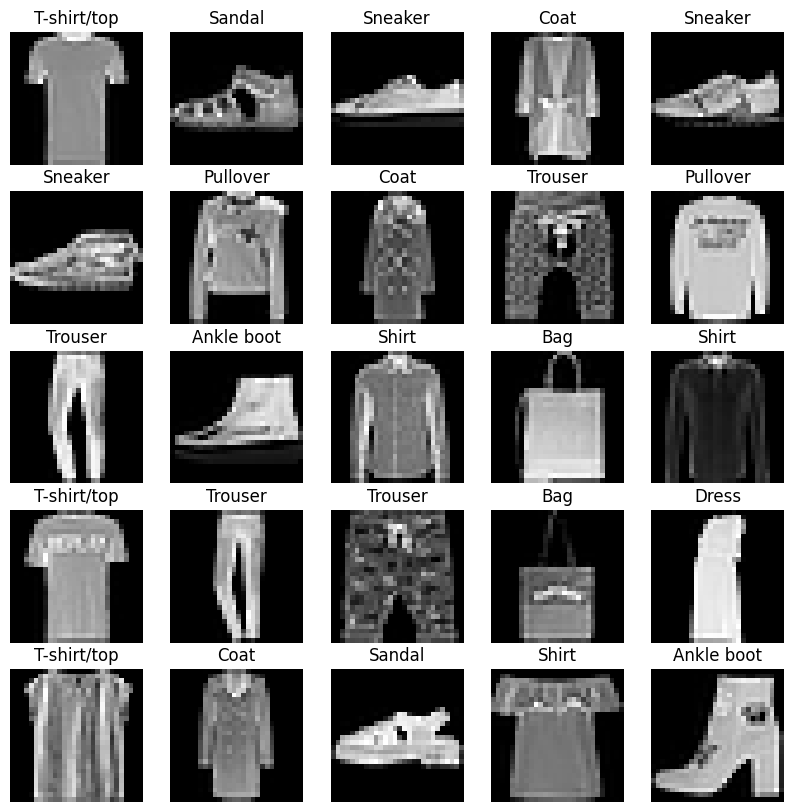

In [17]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

plt.figure(figsize=(10, 10))
for i in range(25):  # Plot first 25 images
    plt.subplot(5, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap='gray')  # Remove channel dim for display
    plt.title(class_names[labels[i]])
    plt.axis('off')
plt.show()

Explanation of Dimensions
Each Fashion-MNIST image has shape (1, 28, 28):

- 1: Single grayscale channel (unlike RGB images with 3 channels).

- 28, 28: Height × width in pixels (28×28 grayscale images).

Why flatten?

Fully connected (dense) layers in neural networks expect 1D feature vectors as input. To feed an image into such layers, flatten the spatial dimensions (1, 28, 28) → (784) (28×28=784 features per image), preserving the information while matching the layer's input requirements. (CNNs avoid full flattening by using convolutional layers instead.)

<font size=7 color="#5499C7">Neural Network Defenition</font>

In [18]:
class FashionMNISTMLP(nn.Module):
    def __init__(self):
        super(FashionMNISTMLP, self).__init__()
        self.flatten = nn.Flatten()                  # 1 x 28 x 28 → 784
        self.fc1 = nn.Linear(784, 256)               # First FC layer
        self.relu1 = nn.ReLU()
        self.fc2 = nn.Linear(256, 128)               # Second FC layer
        self.relu2 = nn.ReLU()
        self.fc3 = nn.Linear(128, 10)                # Output layer (10 classes)

    def forward(self, x):
        x = self.flatten(x)
        x = self.relu1(self.fc1(x))
        x = self.relu2(self.fc2(x))
        x = self.fc3(x)                              # No softmax here
        return x

model = FashionMNISTMLP()

print(model)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"\nTotal trainable parameters: {total_params:,}")

FashionMNISTMLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=784, out_features=256, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=256, out_features=128, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=128, out_features=10, bias=True)
)

Total trainable parameters: 235,146


Brief Explanation of Parameters and Layers

Flatten: Reshapes input from (1, 28, 28) to 784-dimensional vector. No trainable parameters.


- FC1 (784 → 256): Weights: 784 × 256 = 200,704; Biases: 256 → 200,960 params.
Applies linear transformation followed by ReLU to introduce non-linearity and begin learning hierarchical features.


- FC2 (256 → 128): Weights: 256 × 128 = 32,768; Biases: 128 → 32,896 params.
Further transforms the representation, reducing dimensionality while retaining important features via ReLU.


- FC3 (128 → 10): Weights: 128 × 10 = 1,280; Biases: 10 → 1,290 params.
Produces raw scores (logits) for the 10 fashion classes.

Total trainable parameters: 200,960 + 32,896 + 1,290 = 235,146.


The fully connected layers progressively extract and refine features from the flattened image pixels. ReLU activations enable the network to learn complex, non-linear decision boundaries required for accurate multi-class classification. No softmax is used in the model because nn.CrossEntropyLoss expects raw logits and applies log-softmax internally for better numerical stability.

In [19]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

print(criterion)
print(optimizer)

CrossEntropyLoss()
Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


Explanation:

CrossEntropyLoss is used for multi-class classification because it combines the LogSoftmax and Negative Log-Likelihood (NLL) loss functions into one. It directly measures the difference between the predicted probability distribution (raw logits from the last layer) and the true class distribution (one-hot encoded labels). This makes it a standard, efficient, and numerically stable choice for this task, as it effectively penalizes incorrect predictions and guides the model during training.